# Obstacle Mask Generation

This notebook loads an elevation sample and markers, then generates an obstacle mask using randomized superellipses. The obstacle mask uses **0** for valid path cells and **1** for forbidden cells.

In [8]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

In [ ]:
from passage.generate import generate_sample, find_path, _resolve_solver_config, _resolve_obstacle_config
from passage.obstacles import sample_n_from_config, sample_angle_from_config

## Configuration

In [9]:
# Sample generation settings
RESOLUTION = 1024  # 64, 128, 256, 512, 1024, 2048, 4096
SAMPLE_INDEX = 0
DISABLE_IMAGES = True
OVERRIDE_EXISTING = True

# Paths
OUTPUTS_DIR = ROOT / "outputs" / "obstacles"
TILES_DIR = ROOT / "outputs" / "download" / "tiles"
CALIBRATE_PATH = ROOT / "outputs" / "calibrate" / "calibrate.json"
CONFIG_PATH = ROOT / "config" / "config.yaml"

with open(CONFIG_PATH) as f:
    config = yaml.safe_load(f) or {}

# read obstacles config
obstacles_cfg = config.get("obstacles", {})
OBSTACLES_ENABLED = bool(obstacles_cfg.get("enabled", False))
OBSTACLE_RATIO_MAX = float(obstacles_cfg.get("ratio_max", 0.2))
shape_cfg = obstacles_cfg.get("shape", {})
size_cfg = shape_cfg.get("size", {})
OBSTACLE_SIZE_MIN_RATIO = float(size_cfg.get("min_ratio", 0.20))
OBSTACLE_SIZE_MAX_RATIO = float(size_cfg.get("max_ratio", 0.50))
N_CFG = shape_cfg.get("n", {})
N_DISTRIBUTION_CFG = N_CFG.get("distribution", {})

# generation tuning
GENERATION_CFG = obstacles_cfg.get("generation", {})
obstacle_settings = _resolve_obstacle_config(config)

# Obstacle mask generation settings
NUM_MASKS_MAX = 40  # Upper bound constant (used for display/experiments)
NUM_MASKS_TO_GENERATE = 20  # Number of masks to generate and display (<= NUM_MASKS_MAX)

COST_MODEL = (
    config.get("solver", {}).get("grid", {}).get("cost_model")
    or config.get("solver", {}).get("networkx", {}).get("cost_model")
    or config.get("solver", {}).get("pathfinding", {}).get("cost_model")
    or "elevation"
)

# Solver defaults for sample generation read from config
GEN_SOLVER_CONFIG = _resolve_solver_config(config.get("solver", {}))
GEN_SOLVER_CONFIG.setdefault("name", "grid:astar")
GEN_SOLVER_CONFIG.setdefault("diagonal_movement", "always")
GEN_SOLVER_CONFIG.setdefault("weight", 30.0)
GEN_SOLVER_CONFIG.setdefault("cost_model", COST_MODEL)
GEN_SOLVER_CONFIG.setdefault("heuristic", "euclidean")

'euclidean'

In [10]:
# Shape and n distribution config (nested structure)
shape_cfg = obstacles_cfg.get("shape", {})
size_cfg = shape_cfg.get("size", {})
OBSTACLE_SIZE_MIN_RATIO = float(size_cfg.get("min_ratio", 0.20))
OBSTACLE_SIZE_MAX_RATIO = float(size_cfg.get("max_ratio", 0.50))
N_CFG = shape_cfg.get("n", {})
N_DISTRIBUTION_CFG = N_CFG.get("distribution", {})

**Note:** The superellipse exponent `n` may be sampled from different distributions configured under `shape.n.distribution`:

- `log_uniform` (default)
- `uniform`
- `beta`
- `exponential` (new): accepts parameter `lambda` (rate) to bias toward lower values; example: `{"type": "exponential", "lambda": 2.0}`

## Load or Generate Sample

In [11]:
# Validate required inputs
if not CALIBRATE_PATH.exists():
    raise FileNotFoundError(f"Calibration file not found: {CALIBRATE_PATH}. Run 'passage calibrate' first.")
if not TILES_DIR.exists():
    raise FileNotFoundError(f"Tiles directory not found: {TILES_DIR}. Run 'passage download' first.")

# Load calibration data
with open(CALIBRATE_PATH) as f:
    calibration = json.load(f)
global_min = float(calibration["global_min"])
global_max = float(calibration["global_max"])
tile_stats_df = pd.DataFrame(calibration["tile_stats"])

tensor_path = OUTPUTS_DIR / str(RESOLUTION) / "tensors" / f"{SAMPLE_INDEX:010d}.npy"
metadata_path = OUTPUTS_DIR / str(RESOLUTION) / "metadata" / f"{SAMPLE_INDEX:010d}.yaml"

if OVERRIDE_EXISTING or not tensor_path.exists() or not metadata_path.exists():
    OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
    args = (
        SAMPLE_INDEX,
        TILES_DIR,
        OUTPUTS_DIR,
        RESOLUTION,
        tile_stats_df,
        global_min,
        global_max,
        DISABLE_IMAGES,
        GEN_SOLVER_CONFIG,
        obstacle_settings,
    )
    index, success, message, duration = generate_sample(args)
    print(f"Generate sample: success={success}, message='{message}', duration={duration:.2f}s")
    if not success:
        raise RuntimeError("Sample generation failed. Try a different resolution or re-run calibration.")
else:
    print(f"Using existing tensor: {tensor_path}")

tensor = np.load(tensor_path)
elevation_norm = tensor[:, :, 0]
marker_channel = tensor[:, :, 1]
obstacle_channel = tensor[:, :, 2] if tensor.shape[2] > 2 else np.zeros_like(marker_channel)
elevation_raw = elevation_norm * (global_max - global_min) + global_min

print(f"Loaded tensor shape: {tensor.shape}")

2026-01-16 17:35:39.346 | DEBUG    | passage.generate:wrapper:270 - ### ENTER generate_sample()
2026-01-16 17:35:39.348 | DEBUG    | passage.generate:generate_sample:1439 - Loading full grid for center=(49,135) half_tiles=1
2026-01-16 17:35:39.348 | DEBUG    | passage.generate:wrapper:270 - ### ENTER load_tile_grid()
2026-01-16 17:35:39.349 | DEBUG    | passage.generate:wrapper:270 - ### ENTER load_tile()
2026-01-16 17:35:39.356 | DEBUG    | passage.generate:load_tile:954 - Using tile file: /home/t0300081/projects/PASSAGE/passage/outputs/download/tiles/ALPSMLC30_N050E134_DSM.tif
2026-01-16 17:35:39.431 | DEBUG    | passage.generate:wrapper:277 - ### EXIT load_tile() duration=0.0824s
2026-01-16 17:35:39.432 | DEBUG    | passage.generate:wrapper:270 - ### ENTER load_tile()
2026-01-16 17:35:39.435 | DEBUG    | passage.generate:load_tile:954 - Using tile file: /home/t0300081/projects/PASSAGE/passage/outputs/download/tiles/ALPSMLC30_N050E135_DSM.tif
2026-01-16 17:35:39.525 | DEBUG    | pass

Generate sample: success=True, message='Generated sample 0', duration=3.38s
Loaded tensor shape: (1024, 1024, 3)


## Obstacle Generation

In [12]:
def generate_obstacles_mask(
    shape,
    ratio_max,
    size_min_ratio,
    size_max_ratio,
    marker_positions=None,
    rng=None,
    max_attempts=None,
    generation_cfg=None,
):
    """Generate an obstacle mask using randomized superellipses.

    Returns (mask, target_ratio).
    - mask: uint8 array with 0 (free) and 1 (obstacle)
    - target_ratio: randomly drawn in [0, ratio_max]

    Simplified behavior: sizes are drawn between `size_min_ratio` and `size_max_ratio` (no
    additional height caps or external exponent configuration). Procedural tuning is driven
    by `generation_cfg` (max_attempts, candidates_per_mask).
    """
    rng = np.random.default_rng() if rng is None else rng
    height, width = shape
    ratio_max = float(max(0.0, ratio_max))

    marker_positions = [] if marker_positions is None else [tuple(map(int, p)) for p in marker_positions]

    gen = generation_cfg if generation_cfg is not None else obstacles_cfg.get("generation", {})
    max_attempts = int(gen.get("max_attempts", 50)) if max_attempts is None else int(max_attempts)
    candidates_per_mask = int(gen.get("candidates_per_mask", 200))

    for _ in range(max_attempts):
        target_ratio = float(rng.uniform(0.0, ratio_max))
        mask = np.zeros((height, width), dtype=np.uint8)

        print(f"Target ratio: {target_ratio:.4f}")

        if target_ratio <= 0.0:
            return mask, target_ratio

        size_min_ratio = float(max(0.0, size_min_ratio))
        size_max_ratio = float(max(size_min_ratio, size_max_ratio))

        min_w = max(1, int(size_min_ratio * width))
        max_w = max(1, int(size_max_ratio * width))
        min_h = max(1, int(size_min_ratio * height))
        max_h = max(1, int(size_max_ratio * height))

        yy, xx = np.mgrid[0:height, 0:width]

        abort_attempt = False
        for _ in range(candidates_per_mask):
            # Try up to 10 times to sample a candidate that does not overlap markers
            candidate_retry = 0
            while True:
                w = int(rng.integers(min_w, max_w + 1))
                h = int(rng.integers(min_h, max_h + 1))
                cx = int(rng.integers(0, width))
                cy = int(rng.integers(0, height))
                angle = float(sample_angle_from_config(rng))
                n = float(sample_n_from_config(obstacles_cfg, rng))
                print(f"Sampled obstacle params: w={w}, h={h}, cx={cx}, cy={cy}, angle={angle:.2f}, n={n:.2f}")

                x = xx - cx
                y = yy - cy
                cos_a = np.cos(angle)
                sin_a = np.sin(angle)
                xr = x * cos_a + y * sin_a
                yr = -x * sin_a + y * cos_a

                a = max(w / 2.0, 1.0)
                b = max(h / 2.0, 1.0)
                candidate = (np.abs(xr) / a) ** n + (np.abs(yr) / b) ** n <= 1.0

                # If candidate overlaps any marker, retry sampling (up to 10 times)
                if any(candidate[i, j] == 1 for i, j in marker_positions):
                    print("Candidate overlaps marker; retrying...")
                    candidate_retry += 1
                    if candidate_retry < 10:
                        print("Candidate overlaps marker; retrying...")
                        continue  # try another candidate
                    else:
                        # Too many retries for this attempt; abort and try another outer attempt
                        print("Too many candidate retries; aborting this attempt.")
                        abort_attempt = True
                        break

                new_ratio = np.mean(mask | candidate)
                if new_ratio > target_ratio:
                    # Candidate would exceed target coverage; abandon candidate generation for this attempt
                    print(
                        f"New ratio {new_ratio:.4f} exceeds target; abandoning candidate; current ratio {np.mean(mask):.4f}"
                    )
                    abort_attempt = True
                    break

                mask = np.logical_or(mask, candidate).astype(np.uint8)
                print(f"Updated mask coverage ratio: {np.mean(mask):.4f}")
                break  # candidate accepted, move to next candidate

            if abort_attempt:
                print("Aborting current attempt to generate mask; restarting.")
                break

        # ensure no marker is inside mask (safety check)
        if any(mask[i, j] == 1 for i, j in marker_positions):
            print("Final mask overlaps marker; restarting generation.")
            continue

        return mask, target_ratio

    return np.zeros((height, width), dtype=np.uint8), 0.0

Target ratio: 0.2538
Sampled obstacle params: w=199, h=67, cx=209, cy=936, angle=3.91, n=1.24
Updated mask coverage ratio: 0.0077
Sampled obstacle params: w=236, h=216, cx=510, cy=249, angle=1.98, n=12.26
Updated mask coverage ratio: 0.0558
Sampled obstacle params: w=185, h=74, cx=328, cy=269, angle=1.65, n=1.36
Updated mask coverage ratio: 0.0642
Sampled obstacle params: w=24, h=24, cx=830, cy=637, angle=1.41, n=3.07
Updated mask coverage ratio: 0.0647
Sampled obstacle params: w=134, h=80, cx=796, cy=198, angle=5.07, n=1.09
Updated mask coverage ratio: 0.0703
Sampled obstacle params: w=113, h=223, cx=337, cy=298, angle=1.91, n=11.85
Updated mask coverage ratio: 0.0831
Sampled obstacle params: w=114, h=246, cx=866, cy=215, angle=5.65, n=38.99
Updated mask coverage ratio: 0.1063
Sampled obstacle params: w=55, h=21, cx=347, cy=284, angle=1.96, n=33.27
Updated mask coverage ratio: 0.1063
Sampled obstacle params: w=168, h=225, cx=997, cy=788, angle=3.04, n=41.64
Updated mask coverage ratio

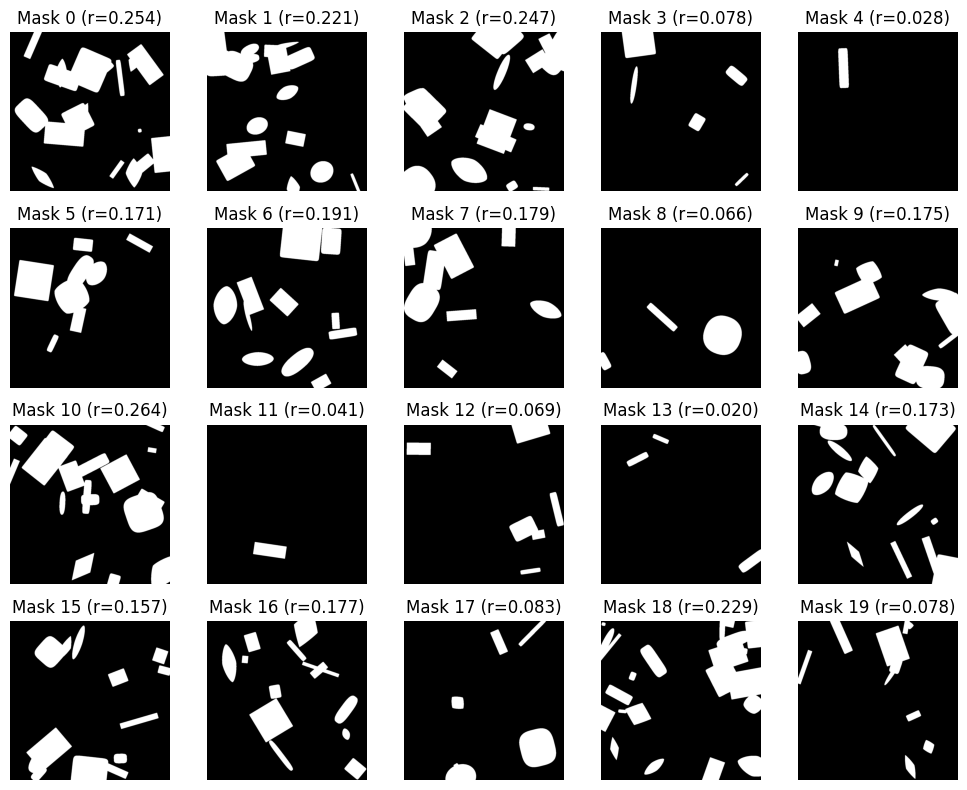

In [13]:
marker_positions = np.argwhere(marker_channel > 0)

# Respect the notebook-level constants and ensure we don't exceed the defined maximum
NUM_MASKS = min(NUM_MASKS_TO_GENERATE, NUM_MASKS_MAX)

masks = []
ratios = []
for i in range(NUM_MASKS):
    mask, ratio = generate_obstacles_mask(
        elevation_raw.shape,
        OBSTACLE_RATIO_MAX,
        OBSTACLE_SIZE_MIN_RATIO,
        OBSTACLE_SIZE_MAX_RATIO,
        marker_positions=marker_positions,
    )
    masks.append(mask)
    ratios.append(ratio)

masks_arr = np.stack(masks, axis=0)

# Choose the first generated mask as the active obstacles_mask for downstream cells
obstacles_mask = masks_arr[0]
tensor_with_obstacles = np.stack([elevation_norm, marker_channel, obstacles_mask], axis=-1)

print(f"Generated {NUM_MASKS} obstacle masks (displaying {NUM_MASKS}).")
print(f"Target obstacle ratio stats: min={min(ratios):.3f}, mean={np.mean(ratios):.3f}, max={max(ratios):.3f}")
print(f"Tensor with obstacles shape: {tensor_with_obstacles.shape}")

# Display the masks in a compact grid gallery
n = masks_arr.shape[0]
cols = min(5, n)
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2))
axes = np.array(axes).reshape(-1)

for idx, ax in enumerate(axes[:n]):
    ax.imshow(masks_arr[idx], cmap="gray")
    ax.set_title(f"Mask {idx} (r={ratios[idx]:.3f})")
    ax.axis("off")

for ax in axes[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## Pathfinding (grid:astar)

2026-01-16 17:35:51.729 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:35:51.730 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:35:51.940 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.2093s, total=0.2093s
2026-01-16 17:35:51.941 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.2107s


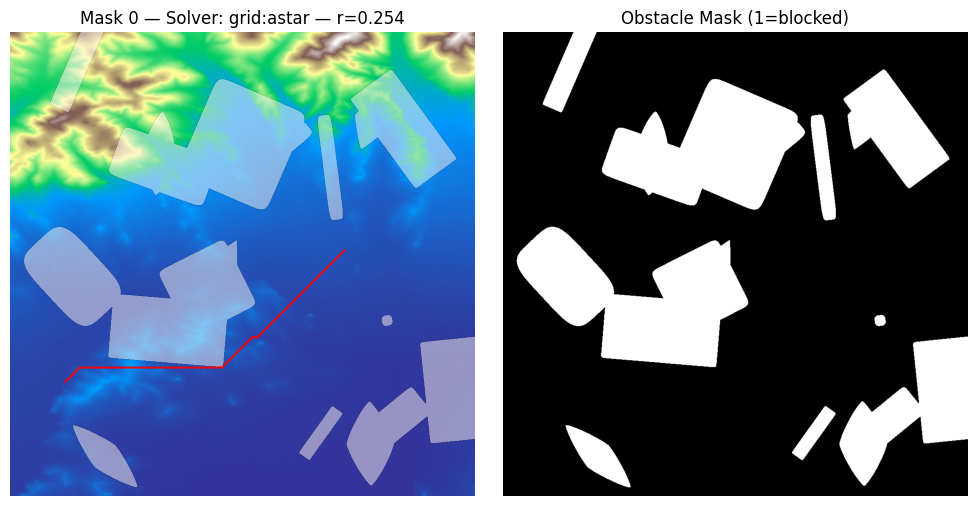

2026-01-16 17:35:52.288 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:35:52.288 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:35:52.680 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=662, solve_time=0.3908s, total=0.3908s
2026-01-16 17:35:52.680 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.3918s


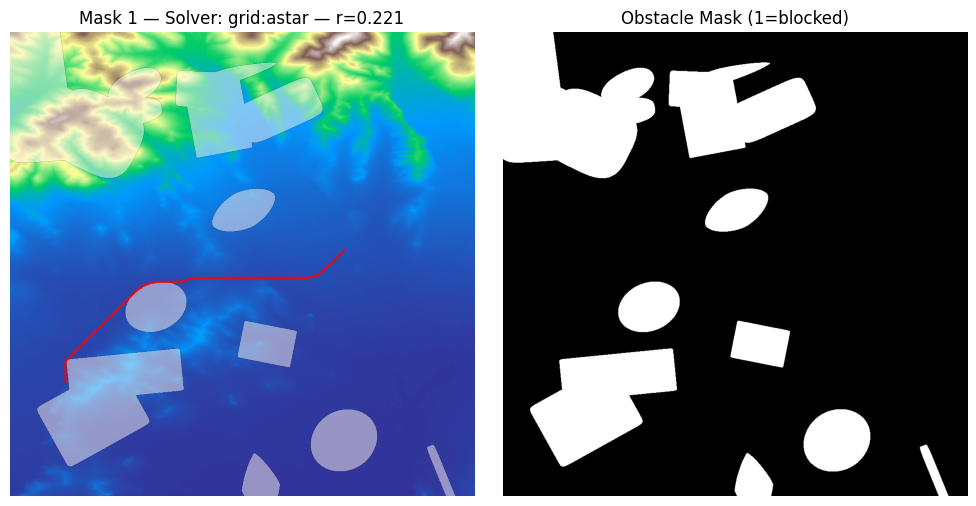

2026-01-16 17:35:52.980 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:35:52.981 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:35:53.226 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.2445s, total=0.2445s
2026-01-16 17:35:53.226 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.2456s


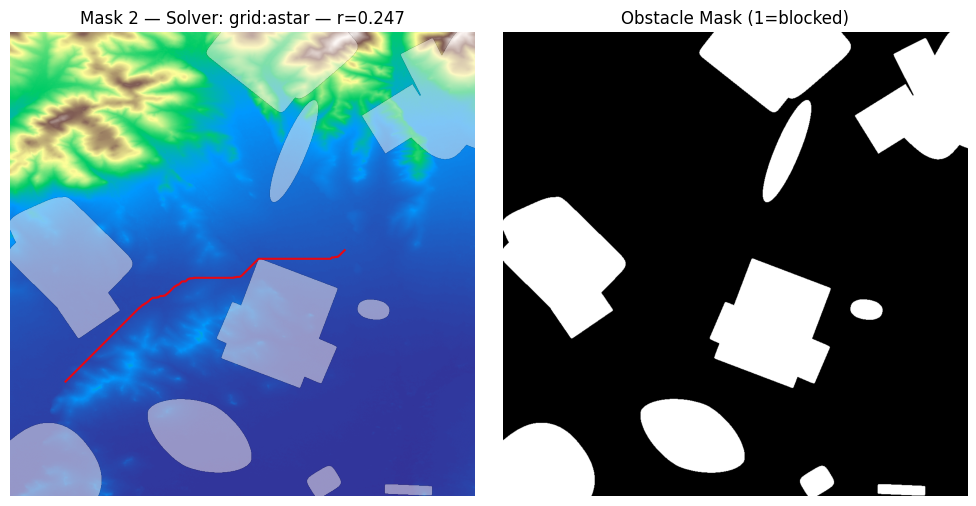

2026-01-16 17:35:53.526 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:35:53.527 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:35:53.870 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.3418s, total=0.3418s
2026-01-16 17:35:53.870 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.3434s


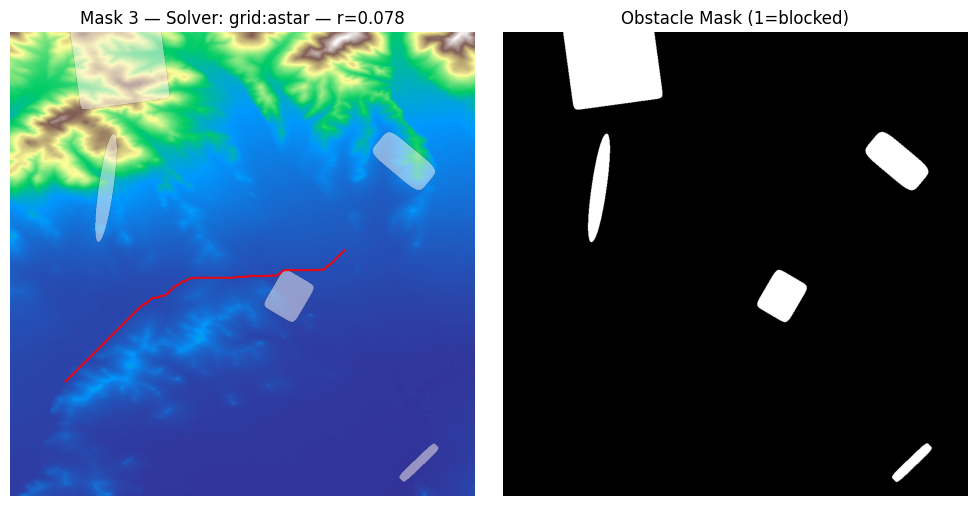

2026-01-16 17:35:54.183 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:35:54.183 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:35:54.584 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.4004s, total=0.4004s
2026-01-16 17:35:54.585 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.4018s


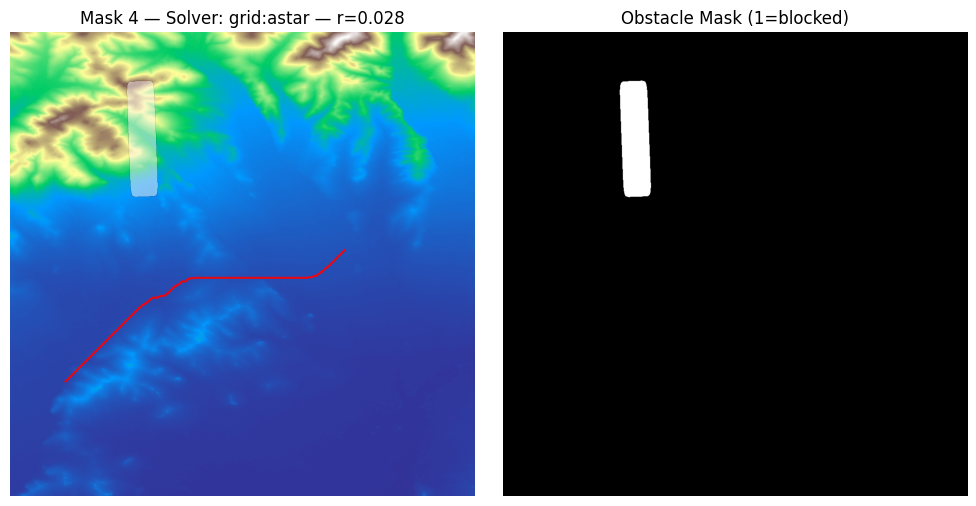

2026-01-16 17:35:54.890 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:35:54.891 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:35:55.165 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.2740s, total=0.2740s
2026-01-16 17:35:55.166 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.2753s


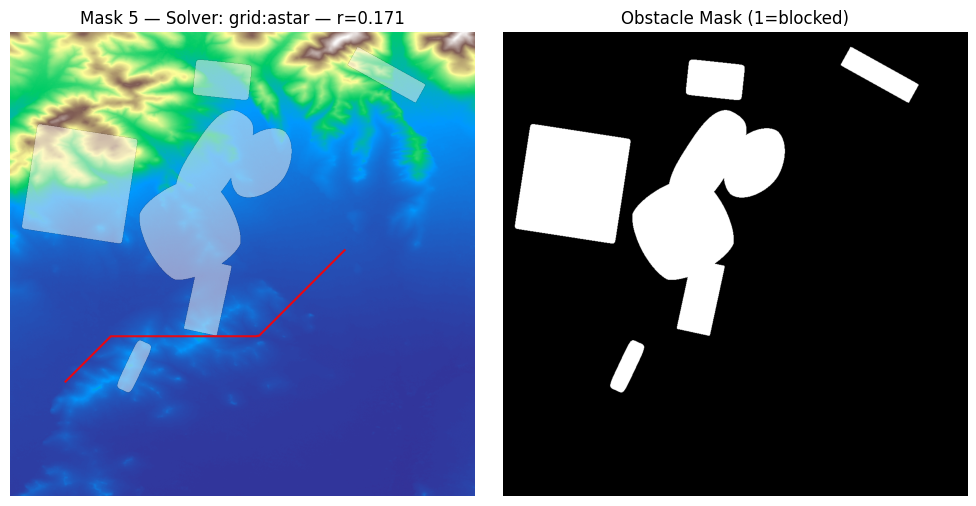

2026-01-16 17:35:55.468 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:35:55.469 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:35:55.833 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.3636s, total=0.3636s
2026-01-16 17:35:55.834 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.3647s


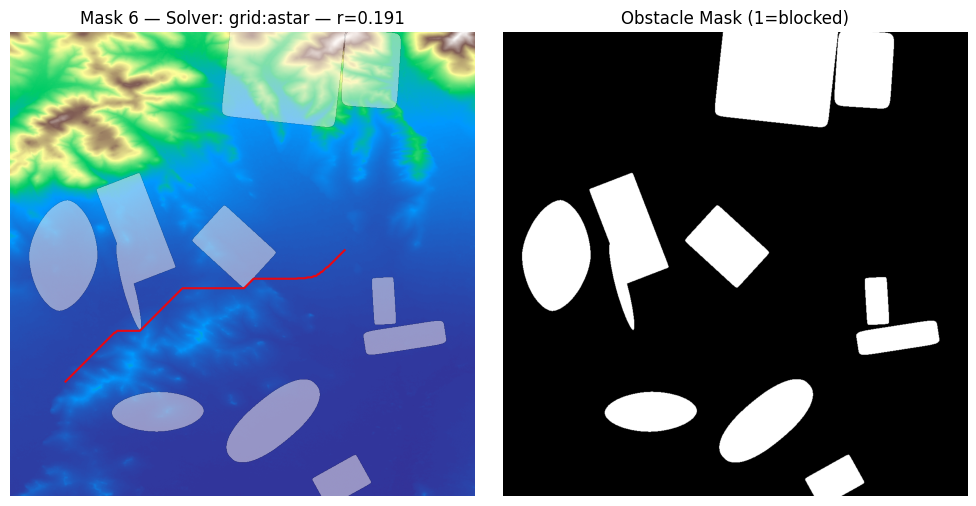

2026-01-16 17:35:56.148 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:35:56.149 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:35:56.514 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.3646s, total=0.3646s
2026-01-16 17:35:56.514 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.3656s


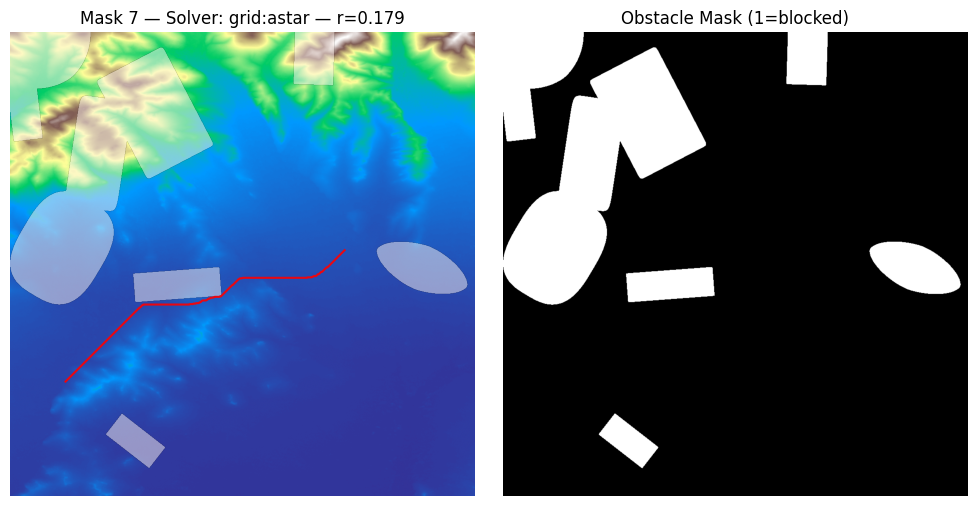

2026-01-16 17:35:56.828 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:35:56.828 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:35:57.200 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.3713s, total=0.3713s
2026-01-16 17:35:57.201 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.3723s


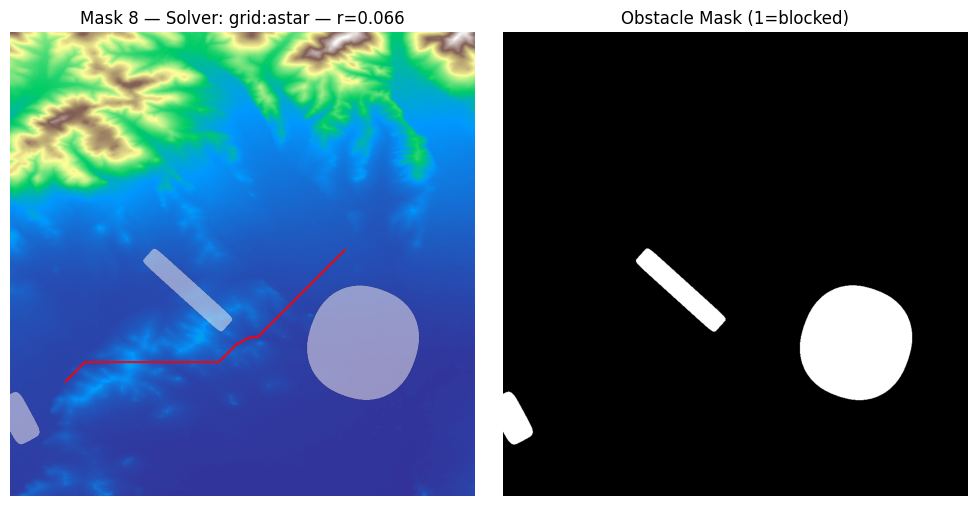

2026-01-16 17:35:57.492 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:35:57.493 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:35:58.017 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.5232s, total=0.5232s
2026-01-16 17:35:58.017 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.5246s


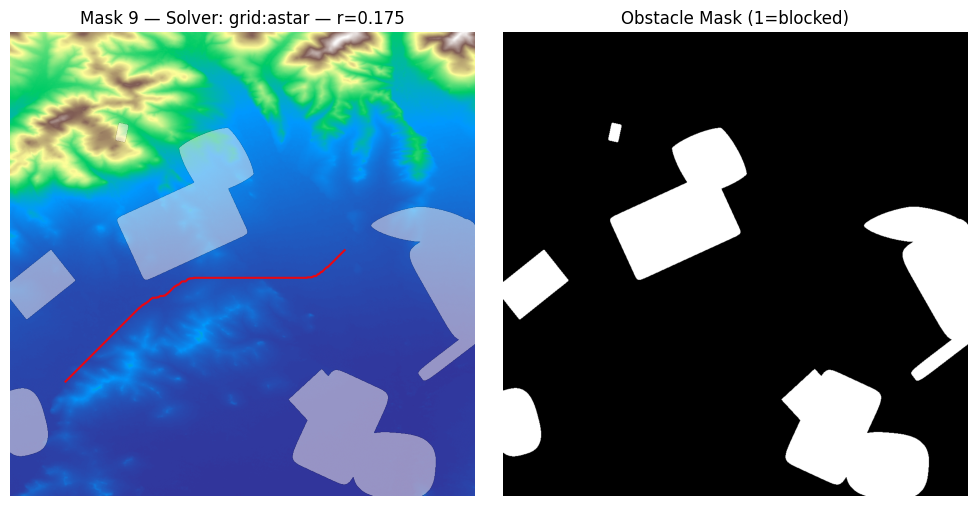

2026-01-16 17:35:58.324 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:35:58.325 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:35:58.713 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.3880s, total=0.3880s
2026-01-16 17:35:58.714 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.3890s


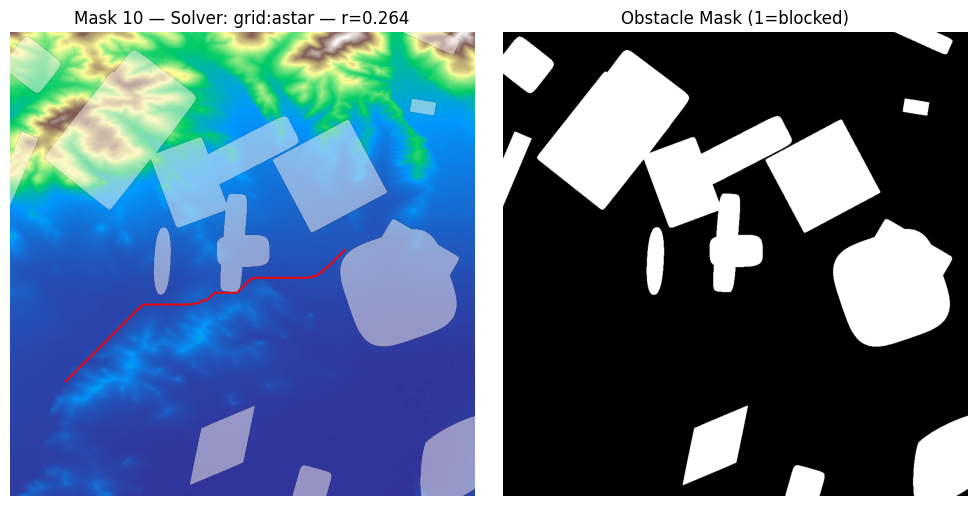

2026-01-16 17:35:59.034 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:35:59.035 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:35:59.517 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.4814s, total=0.4814s
2026-01-16 17:35:59.517 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.4826s


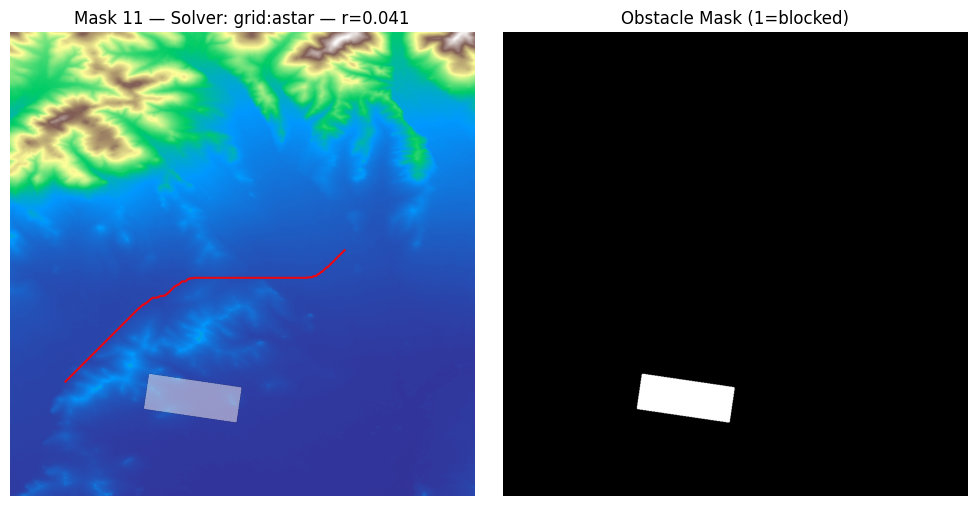

2026-01-16 17:35:59.841 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:35:59.842 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:36:00.287 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.4445s, total=0.4445s
2026-01-16 17:36:00.287 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.4457s


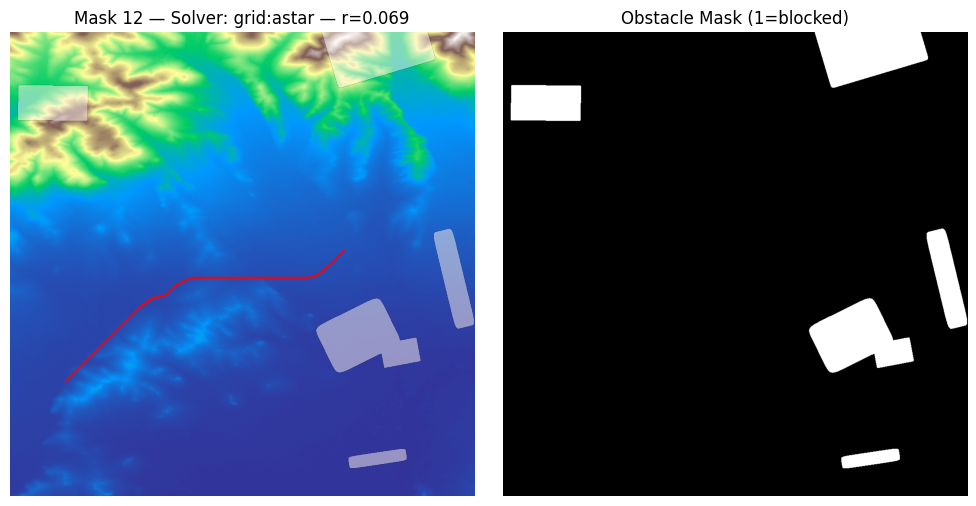

2026-01-16 17:36:00.608 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:36:00.609 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:36:01.113 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.5038s, total=0.5038s
2026-01-16 17:36:01.113 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.5049s


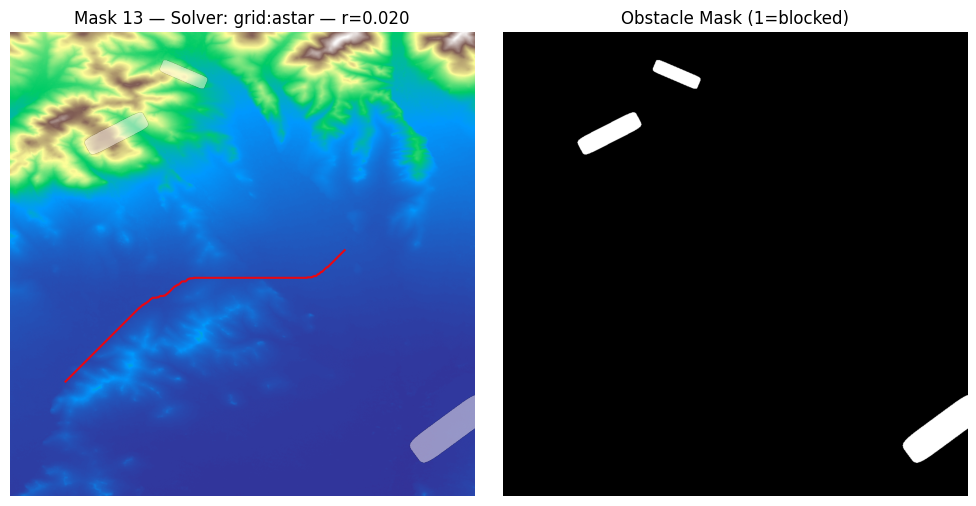

2026-01-16 17:36:01.444 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:36:01.445 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:36:01.983 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.5368s, total=0.5368s
2026-01-16 17:36:01.984 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.5389s


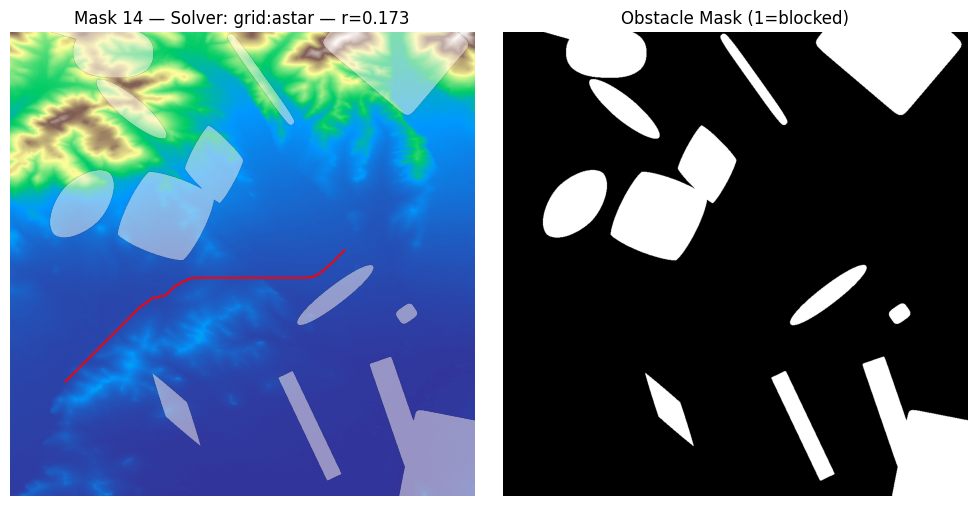

2026-01-16 17:36:02.322 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:36:02.323 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:36:02.962 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.6377s, total=0.6377s
2026-01-16 17:36:02.963 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.6397s


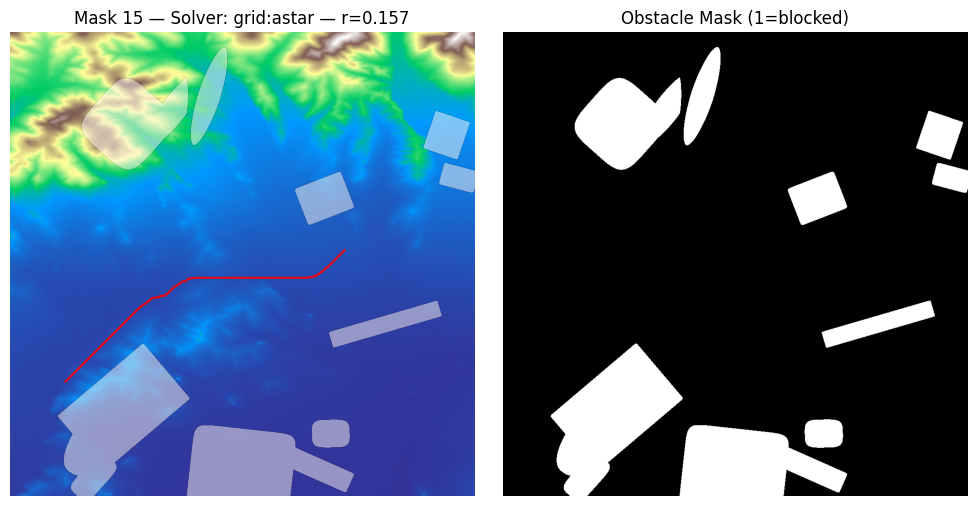

2026-01-16 17:36:03.321 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:36:03.321 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:36:03.664 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=635, solve_time=0.3423s, total=0.3423s
2026-01-16 17:36:03.665 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.3434s


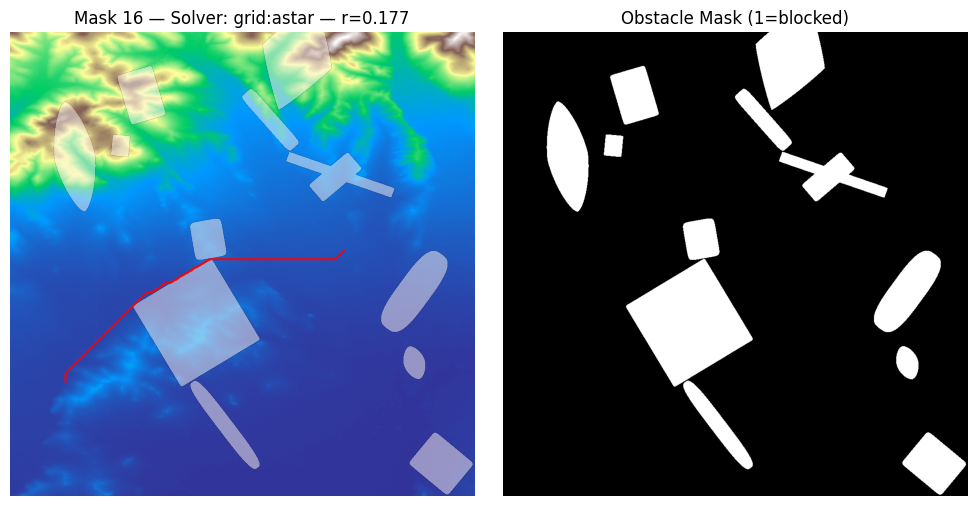

2026-01-16 17:36:03.985 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:36:03.986 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:36:04.499 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.5130s, total=0.5130s
2026-01-16 17:36:04.501 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.5149s


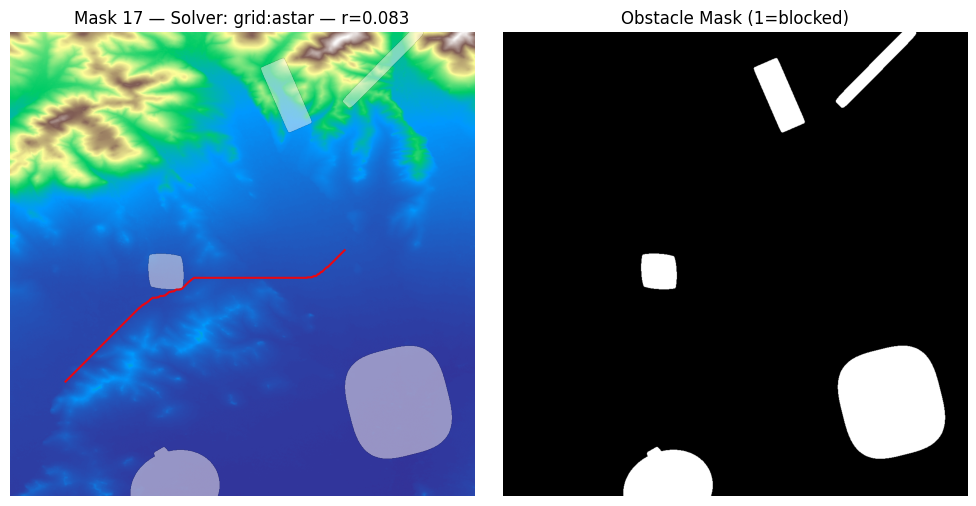

2026-01-16 17:36:04.810 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:36:04.811 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:36:05.305 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.4936s, total=0.4936s
2026-01-16 17:36:05.306 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.4948s


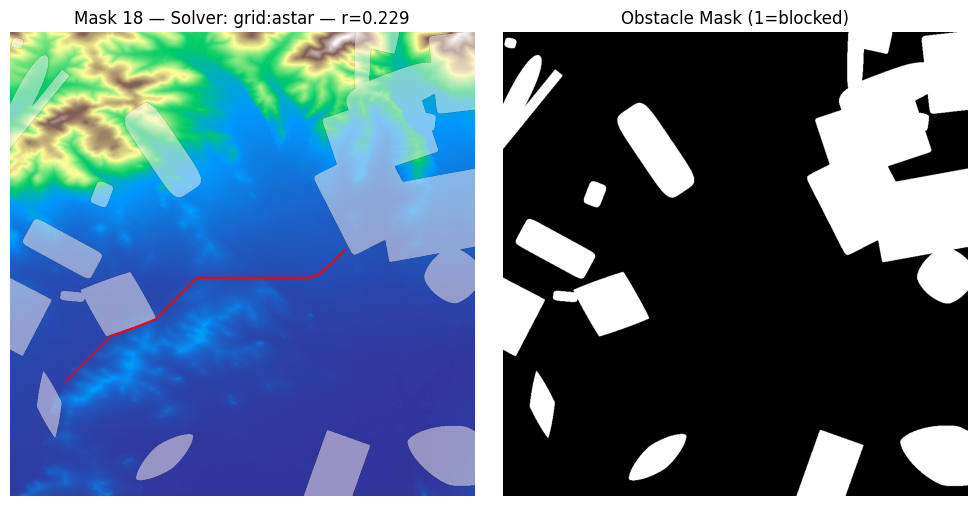

2026-01-16 17:36:05.609 | DEBUG    | passage.generate:wrapper:270 - ### ENTER find_path()
2026-01-16 17:36:05.610 | DEBUG    | passage.generate:find_path:532 - find_path: backend=grid, solver=grid_astar, diagonal=always, weight=1000.0, heuristic=euclidean, cost_model=elevation, graph_backend=edges, grid_size=(1024, 1024), start=(np.int64(481), np.int64(738)), end=(np.int64(771), np.int64(122))
2026-01-16 17:36:06.144 | DEBUG    | passage.generate:find_path:549 - Grid solver finished: path_len=617, solve_time=0.5334s, total=0.5334s
2026-01-16 17:36:06.144 | DEBUG    | passage.generate:wrapper:277 - ### EXIT find_path() duration=0.5346s


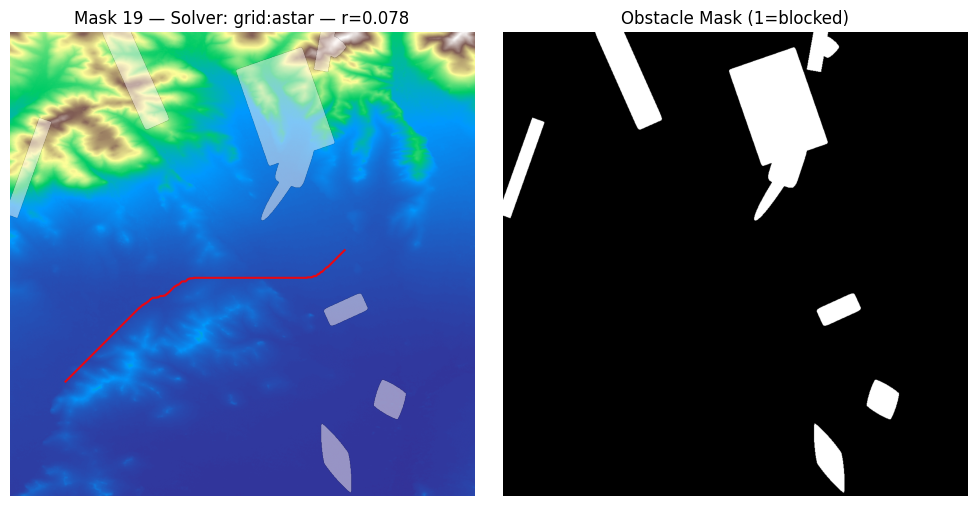

Pathfinding summary:
 index    ratio  path_len    time_ms
     0 0.253842       617 211.824532
     1 0.220725       662 392.587735
     2 0.247421       617 246.422281
     3 0.077936       617 344.277823
     4 0.028312       617 402.904367
     5 0.171134       617 276.777945
     6 0.190984       617 365.626433
     7 0.179068       617 366.482247
     8 0.066180       617 373.129892
     9 0.175141       617 526.456588
    10 0.263861       617 389.841416
    11 0.041291       617 483.984711
    12 0.069023       617 447.217661
    13 0.019863       617 505.723356
    14 0.172893       617 540.287118
    15 0.156974       617 641.442704
    16 0.177266       635 344.532713
    17 0.083158       617 516.235913
    18 0.228979       617 495.922828
    19 0.078234       617 535.714391


In [14]:
import time

marker_positions = np.argwhere(marker_channel > 0)
if marker_positions.shape[0] < 2:
    raise RuntimeError("Expected at least two markers in marker channel.")

start = tuple(marker_positions[0])
end = tuple(marker_positions[1])

# Resolve solver config from config.yaml (supports common + backend sections)
solver_config = _resolve_solver_config(config.get("solver", {}))
# Ensure sensible defaults
solver_config.setdefault("diagonal_movement", "always")
solver_config.setdefault("weight", 30.0)
solver_config.setdefault("cost_model", COST_MODEL)
solver_config.setdefault("heuristic", "euclidean")
solver_name = solver_config.get("name", "grid:astar")

# Penalize obstacle cells heavily to discourage traversal
obstacle_penalty = float(obstacle_settings.get("obstacle_penalty", 1e6))

# Run pathfinding and visualize for each generated mask
mask_results = []
for idx in range(masks_arr.shape[0]):
    m = masks_arr[idx]

    masked_elevation = elevation_raw.copy()
    masked_elevation[m == 1] = masked_elevation.max() + obstacle_penalty

    t0 = time.perf_counter()
    path = find_path(masked_elevation, start, end, solver_config)
    elapsed_ms = (time.perf_counter() - t0) * 1000

    mask_results.append({"index": idx, "ratio": ratios[idx], "path": path, "time_ms": elapsed_ms})

    # Visualization for this mask
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(elevation_norm, cmap="terrain")
    ax[0].imshow(np.ma.masked_where(m == 0, m), cmap="Reds", alpha=0.5)

    if path:
        path_arr = np.array(path)
        ax[0].plot(path_arr[:, 1], path_arr[:, 0], "r-", linewidth=1.5, alpha=0.9, label="Path")

    ax[0].set_title(f"Mask {idx} — Solver: {solver_name} — r={ratios[idx]:.3f}")
    ax[0].axis("off")

    ax[1].imshow(m, cmap="gray")
    ax[1].set_title("Obstacle Mask (1=blocked)")
    ax[1].axis("off")

    plt.tight_layout()
    plt.show()

# Summary table

summary = pd.DataFrame(
    [
        {"index": r["index"], "ratio": r["ratio"], "path_len": len(r["path"]), "time_ms": r["time_ms"]}
        for r in mask_results
    ]
)
print("Pathfinding summary:")
print(summary.sort_values("index").to_string(index=False))